In [259]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from skimage import data
from skimage.filters import threshold_otsu

DYSKRETYZACJA

Zad 1, 2
Przygotuj funkcję generującą zdyskretyzowany sygnał sinus na podstawie parametrów:
• Częstotliwość sygnału f
• Częstotliwość próbkowania Fs
Funkcja powinna zwracać tablice:
• t - tablicę ”czasu” zakres od 0 do 1 z krokiem równym częstości próbkowania: dt = 1 / Fs
• s - wartości wygenerowanego sygnału sinus: s (t) = sin (2πf t)

In [260]:
def discSin(f, fs):
    dt = 1 / fs
    t = np.arange(0, 1, dt)
    s = np.sin(2 * np.pi * f * t)
    
    return t, s

Zad 3
Wyświetl wykresy zawierające sygnał o częstotliwości 10Hz za pomocą
próbkowania: 20Hz, 21Hz, 30Hz, 45Hz, 50Hz, 100Hz, 150Hz, 200Hz, 250Hz, 1000Hz

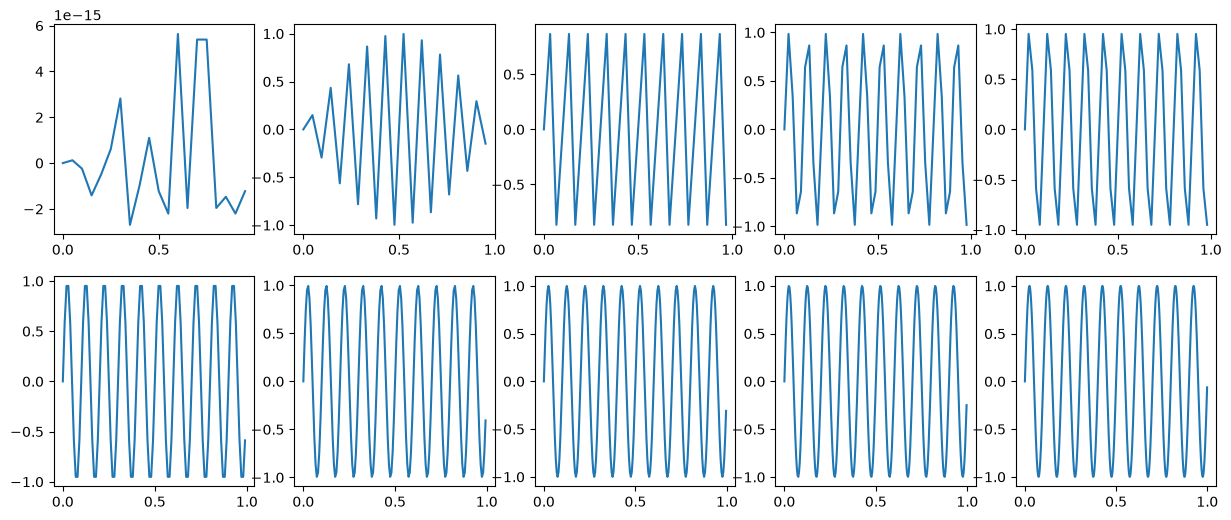

In [261]:
fsList = [20, 21, 30, 45, 50, 100, 150, 200, 250, 1000]
_, plots = plt.subplots(2, 5, figsize=(15, 6))

for fs, plot in zip(fsList, plots.flat):
    t, s = discSin(10, fs)
    plot.plot(t, s)

Zad 4
Czy istnieje twierdzenie, które określa z jaką częstotliwością należy próbkować, aby móc wiernie odtworzyć sygnał? Jak się nazywa?

Twierdzenie o próbkowaniu Nyquista–Shannona.

Zad 5
Jak nazywa się zjawisko, które z powodu błędnie dobranej częstotliwości próbkowania powoduje błędną interpretację sygnału?

Aliasing.

Zad 6
Znajdź za pomocą internetu obraz, na którym występuje wskazane zjawisko (przy wyświetlaniu go w znacznie mniejszej rozdzielczości).

example.png

Zad 7
Sprawdź jak python radzi sobie z wyświetleniem takiego obrazu i jakie opcje można przy tym użyć.

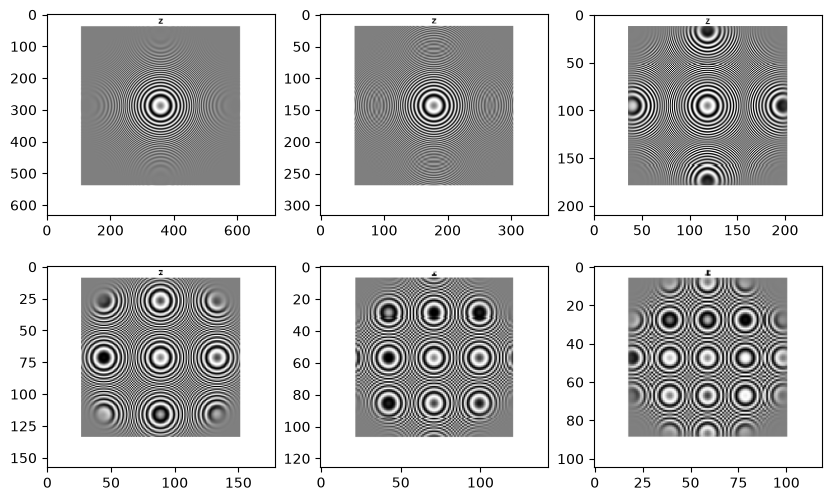

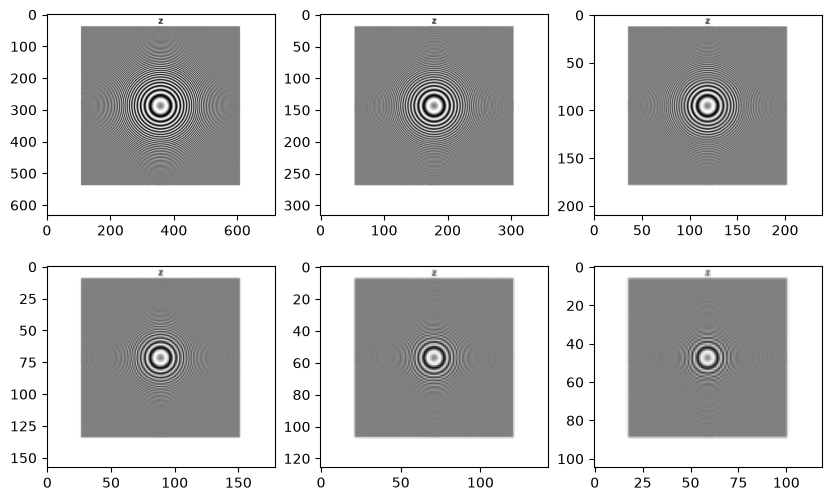

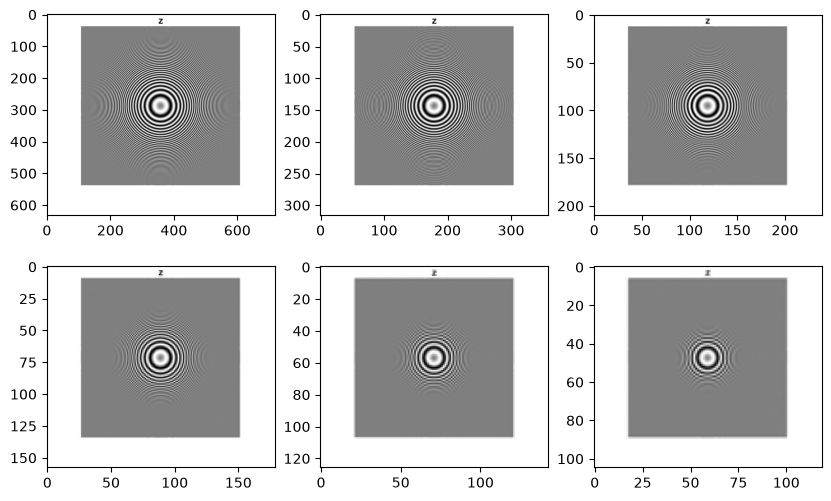

In [262]:
img = Image.open("example.png")

_, imagesNearest = plt.subplots(2, 3, figsize=(10, 6))
_, imagesBilinear = plt.subplots(2, 3, figsize=(10, 6))
_, imagesBiCubic = plt.subplots(2, 3, figsize=(10, 6))

for i, image in enumerate(imagesNearest.flat):
    alia = img.resize((img.width // (i + 1), img.height // (i + 1)), Image.Resampling.NEAREST)
    image.imshow(alia)

for i, image in enumerate(imagesBilinear.flat):
    alia = img.resize((img.width // (i + 1), img.height // (i + 1)), Image.Resampling.BILINEAR)
    image.imshow(alia)

for i, image in enumerate(imagesBiCubic.flat):
    alia = img.resize((img.width // (i + 1), img.height // (i + 1)), Image.Resampling.BICUBIC)
    image.imshow(alia)

KWANTYZACJA

Zad 1
Wczytaj wcześniej znaleziony obrazek

In [263]:
img = plt.imread("robal.png")

Zad 2
Wykonaj polecenie, które zwróci ile wymiarów ma wczytana macierz (obrazek)

In [264]:
print(img.ndim)

3


Zad 3
Wykonaj polecenie, które zwróci iloma wartościami jest opisywany pojedynczy piksel (inaczej: z ilu wartości składa się najgłębszy wymiar)

In [265]:
print(img.shape)
print(img.shape[2])

(918, 611, 3)
3


Zad 4
Przekształć obraz do skali szarości za pomocą 3 różnych metod (zapisz jako 3 różne macierze):
• Wyznaczenie jasności piksela: (max(R, G, B) + min(R, G, B))/2
• Uśrednienie wartości piksela: (R + G + B)/3
• Wyznaczenie luminancji piksela: 0.21R + 0.72G + 0.07B

In [266]:
height = img.shape[0]
width = img.shape[1]

grayImages = []
for _ in range(3):
    grayImages.append(np.zeros((height, width)))

for row, pixels in enumerate(img):
    for col, pixel in enumerate(pixels):
        r, g, b = pixel
        grayImages[0][row][col] = (max(pixel) + min(pixel)) / 2
        grayImages[1][row][col] = sum(pixel) / 3
        grayImages[2][row][col] = 0.21 * r + 0.72 * g + 0.07 * b

Zad 5
Wygeneruj histogram dla każdego z otrzymanych „szarych” obrazów (funkcja histogram z pakietu numpy)

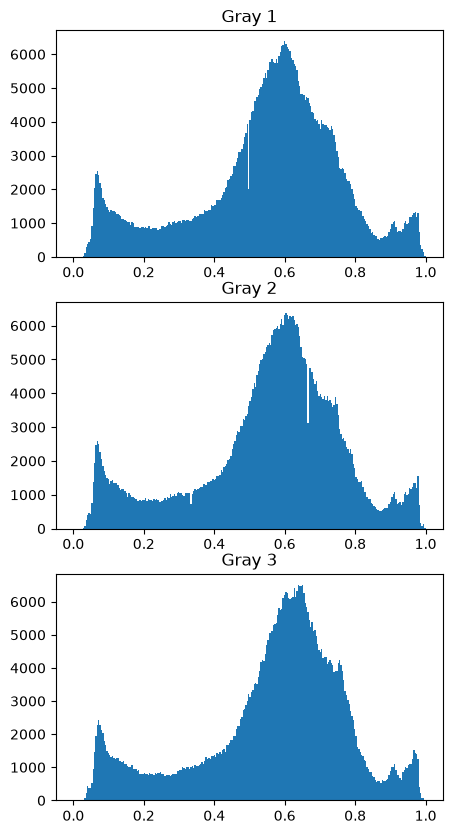

In [267]:
histograms, plots = plt.subplots(3, 1, figsize=(5, 10))

for i, plot in enumerate(plots.flat):
    plot.hist(grayImages[i].ravel(), bins=256, range=(0,1))
    plot.set_title(f"Gray {i + 1}")

Zad 6
Dla dowolnego z wygenerowanych obrazów, za pomocą parametru bins zredukuj liczbę kolorów na histogramie do 16 i wyświetl zakresy nowych kolorów

Nowy zakres kolorów:
[0.0, 0.0625)
[0.0625, 0.125)
[0.125, 0.1875)
[0.1875, 0.25)
[0.25, 0.3125)
[0.3125, 0.375)
[0.375, 0.4375)
[0.4375, 0.5)
[0.5, 0.5625)
[0.5625, 0.625)
[0.625, 0.6875)
[0.6875, 0.75)
[0.75, 0.8125)
[0.8125, 0.875)
[0.875, 0.9375)
[0.9375, 1.0)


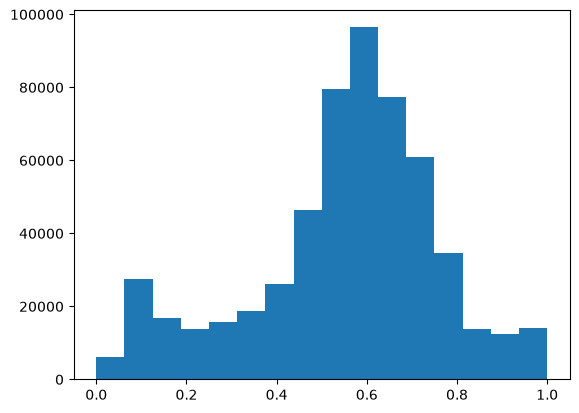

In [268]:
hist16 = plt.hist(grayImages[0].ravel(), bins=16, range=(0,1))

ranges = hist16[1]

print("Nowy zakres kolorów:")
for i in range(len(ranges) - 1):
    print(f"[{ranges[i]}, {ranges[i + 1]})")

Zad 7
Stwórz kolejną macierz (obrazek) ze zredukowaną liczbą kolorów (jako nową wartość piksela przyjmnij środek przedziału zwróconego przez funkcję histogramu)

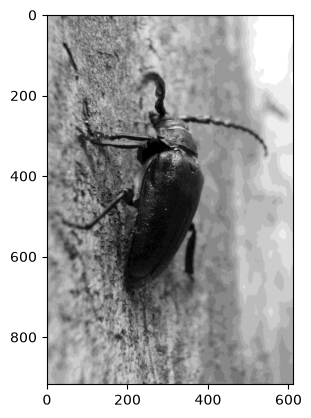

In [269]:
gray16 = np.zeros((height, width))
indexes = np.digitize(grayImages[0], ranges)
halfRange = ranges[1] / 2

for row in range(len(gray16)):
    for col in range(len(gray16[0])):
        gray16[row][col] = ranges[indexes[row][col] - 1] + halfRange
    
plt.imshow(gray16, cmap="gray")



Zad 8
Wyświetl wszystkie obrazy i ich histogramy

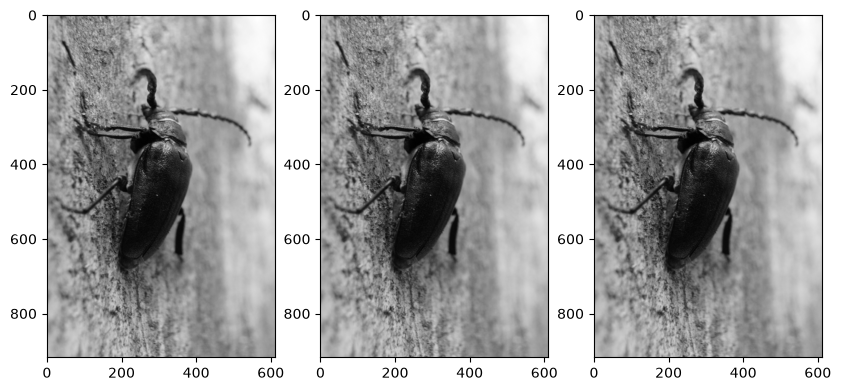

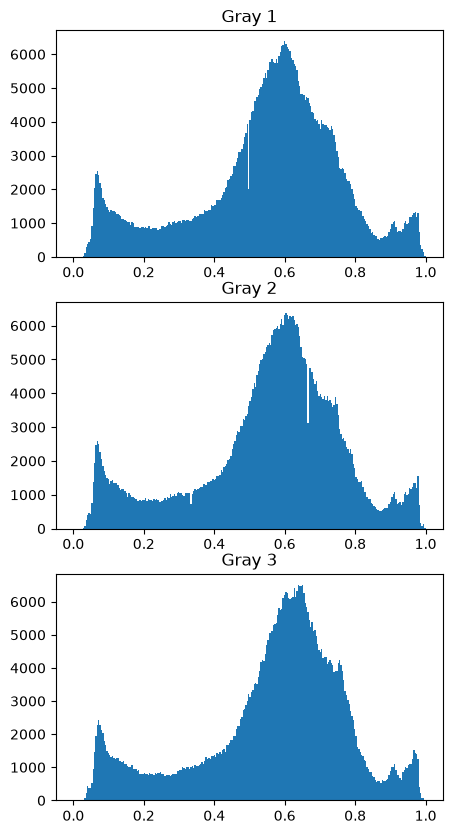

In [270]:

_, plots = plt.subplots(1, 3, figsize=(10, 6))

for plot in plots.flat:
    for image in grayImages:
        plot.imshow(image, cmap="gray")

plt.figure(histograms)
plt.show()

BINARYZACJA 

Zad 1
Pobierz z internetu obraz przedstawiający obiekt na niejednorodnym tle (np. gradiencie)

In [271]:
img = plt.imread("robal.png")

Zad 2
Wczytaj obraz, zamień go na skalę szarości za pomocą jednej z wcześniej stosowanych metod i wygeneruj histogram

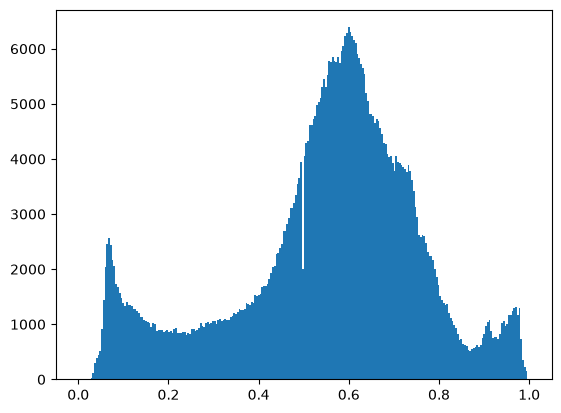

In [306]:
plt.hist(grayImages[0].ravel(), bins=256, range=(0,1));

Zad 3
Napisz funkcję, która na podstawie histogramu określi punkt progowania (zazwyczaj lokalne minimum między dwoma ‘klasami‘ kolorów, tak jak na poniższym obrazku’)

In [305]:
thresh = threshold_otsu(grayImages[0])
print(thresh)

0.44148285719711566


Zad 4
Zbinaryzuj (ustaw wartości na 0 lub 1) wartości pikseli obrazka zgodnie z otrzymanym progiem

In [304]:
binary = grayImages[0] > thresh
print(binary)

[[ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 ...
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]]


Zad 5
Wyświetl obraz z wysegmentowanym obiektem (segmentacja, czyli usunięcie niepotrzebnych elementów, jak np. tła i uwypukleniu tych ważniejszych)

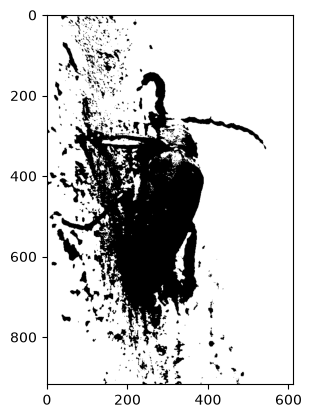

In [303]:
plt.imshow(binary, cmap="gray");


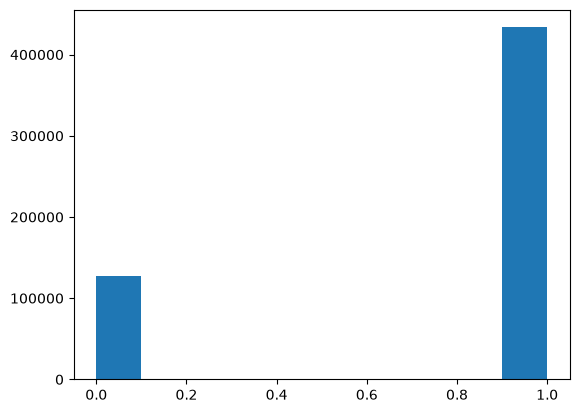

In [301]:
plt.hist(binary.ravel(), range=(0,1));